In [180]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

### Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.
Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [181]:
df = pd.read_csv('../../amz_uk_price_prediction_dataset.csv')

In [182]:
print(df.columns)

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')


In [183]:
#calculate crosstab
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
#look at proportions
crosstab_result_prop = pd.crosstab(df['category'], df['isBestSeller'],normalize='index')
#rank by isBestSeller is True
crosstab_result_prop.iloc[:,-1].sort_values(ascending=False)
#Get top 5 categories
crosstab_result_prop.iloc[:,-1].sort_values(ascending=False).index[:5]

Index(['Grocery', 'Smart Home Security & Lighting', 'Health & Personal Care',
       'Mobile Phone Accessories', 'Power & Hand Tools'],
      dtype='object', name='category')

In [184]:
from scipy.stats import chi2_contingency

chi2_statistic, chi2_p_value, _, expected_freq = chi2_contingency(crosstab_result)

if chi2_p_value< 0.05:
    print(f'result is significant, p={chi2_p_value}')
else:
    print(f'result is not significant, p={chi2_p_value}')

result is significant, p=0.0


In [185]:
from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(crosstab_result, method="cramer")

0.1222829439760564

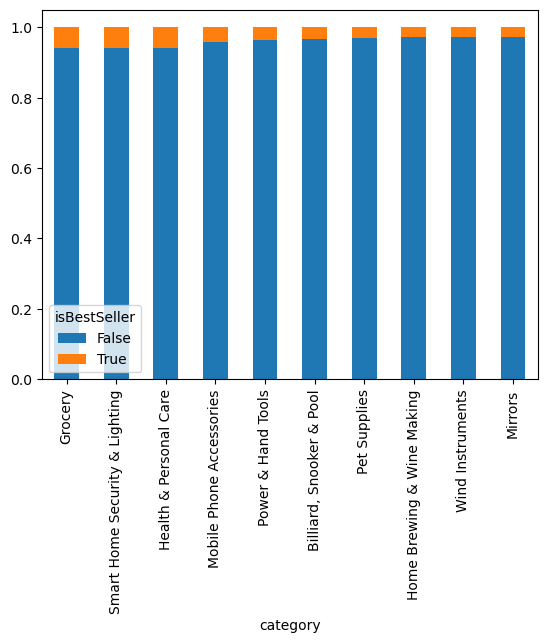

In [186]:
top_10=crosstab_result_prop.iloc[:,-1].sort_values(ascending=False).index[:10]
crosstab_result_prop.loc[top_10,:].plot(kind="bar", stacked=True);

The Cramér's V value of 0.122 suggests a weak association between the two variables. 
Though statistically significant, the strength of this relationship is not very strong in practical terms.

#### Insight Report:
Best-sellers are most prevalent in the following categories (in order of prevalence): 'Grocery', 'Smart Home Security & Lighting', 'Health & Personal Care','Mobile Phone Accessories', 'Power & Hand Tools'
Though they are most common in the category Grocery, only approximately 6 percent of these products are best-sellers. A chi-square test determined a signficant relationship between bestseller  status and category, though the Cramer's V test subsequently determined that the association was weak. 

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.
Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.
Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [201]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Define wiskers for the outliers
    lower_whisker = Q1 - 1.5 * IQR
    upper_whisker = Q3 + 1.5 * IQR

    # Identify the outliers
    # data[(data < lower_whisker) | (data > upper_whisker)] = np.nan
    outliers = data[(data < lower_whisker) | (data > upper_whisker)]
    filtered = np.where(
    (data < lower_whisker) | (data > upper_whisker), np.nan, data)

    return filtered,outliers

data_series = df['price']  
df['price'],outliers = tukeys_test_outliers(data_series)

<Axes: xlabel='price', ylabel='category'>

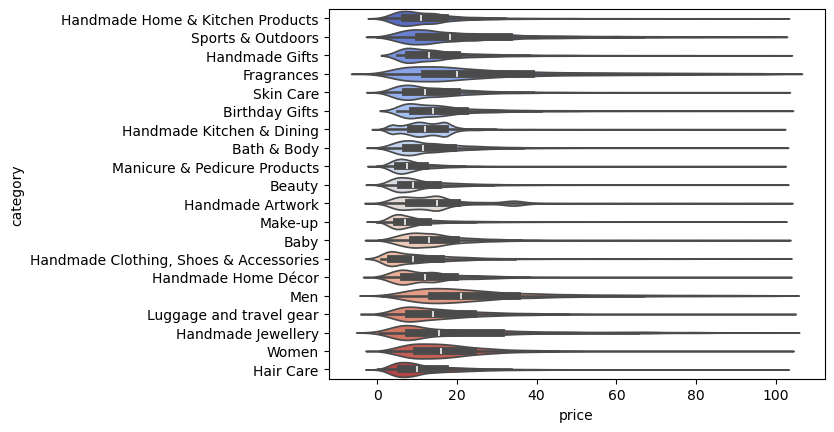

In [188]:
list_top_20 = df.category.value_counts(ascending=False)[:20].index
data= df.loc[df.category.isin(list_top_20)]
sns.violinplot(data=data, x='price', y='category', palette="coolwarm", hue='category', legend=False)

In [189]:
df.groupby('category')['price'].agg('median').sort_values(ascending=False)
#though the highest median in the filtered figure is for the category men, in the unfiltered data the highest median is Desktop PCs.

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

<Axes: ylabel='category'>

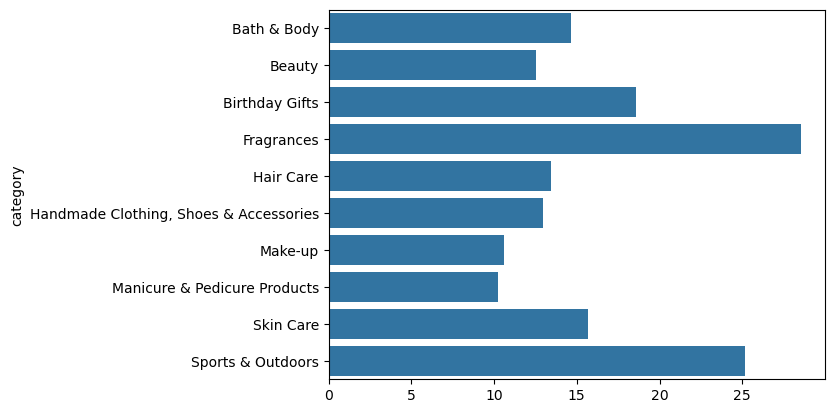

In [190]:
list_top_10 = df.category.value_counts(ascending=False)[:10].index
data1= df.groupby(df[df.category.isin(list_top_10)].category)['price'].agg('mean')
sns.barplot(y=data1.index, x=data1.values,  legend=False)

In [191]:
df.groupby('category')['price'].agg('mean').sort_values(ascending=False)
#from the filtered data, fragrances has the highest average, but across the data Motherboards has the highest average.

category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

<Axes: xlabel='stars', ylabel='category'>

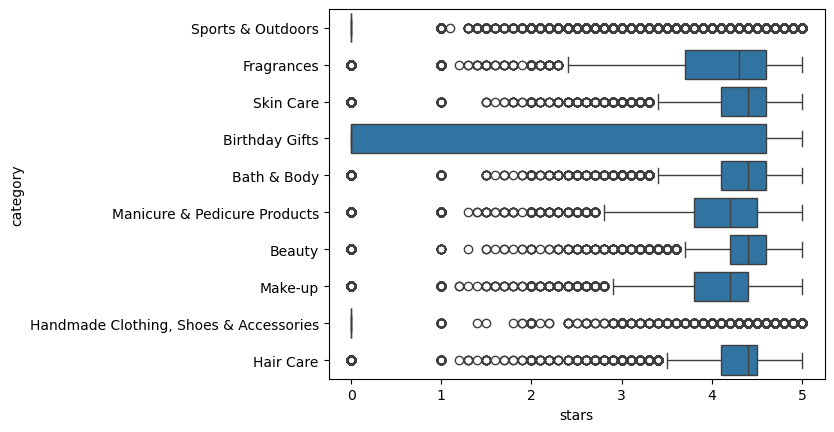

In [192]:
data2= df.loc[df.category.isin(list_top_10)]
sns.boxplot(data=data2, y='category',x='stars')
#Inspect values
#data4.groupby('category')['stars'].agg('median').sort_values(ascending=False)

In [193]:
df.groupby('category')['stars'].agg('median').sort_values(ascending=False)
#Computer Memory has the highest median rating

category
Computer Memory                4.7
Hobbies                        4.6
Beer, Wine & Spirits           4.6
Laptop Accessories             4.6
Kids' Play Figures             4.6
                              ... 
KVM Switches                   0.0
Karaoke Equipment              0.0
Lab & Scientific Products      0.0
Laptops                        0.0
eBook Readers & Accessories    0.0
Name: stars, Length: 296, dtype: float64

#### Insights:
Outliers were removed from the data before analysis was carried out. Amongst top selling categories, the median price largely fell between 10 and 20 dollars, however, the highest median for any category was for Desktop PCs. Motherboards was also found to have the highest mean, though of the top 10 categories Fragrances had the highest mean.

When examining the association between category and rating, amongst the top 10 categories Bath & Body, Beauty, Hair Care and Skin Care shared the highest median value. Computer Memory was found to have the highest median rating across all categories.


### Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?
Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

In [194]:
df.price.corr(df['stars'], method='pearson')
#no, the correlation is insignificant.

np.float64(-0.0776729987818137)

<Axes: xlabel='stars', ylabel='price'>

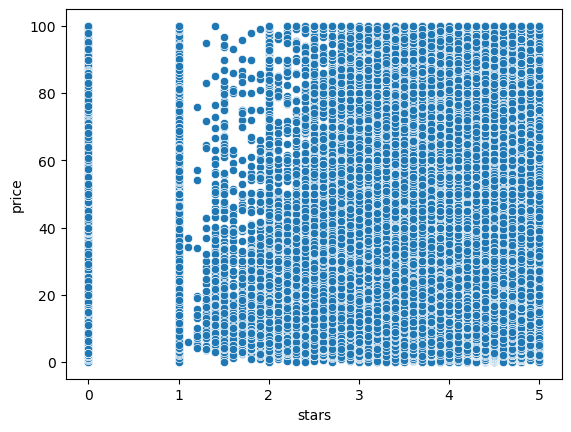

In [195]:
sns.scatterplot(y=df.price, x=df.stars)
#we don't see a relationship, as there are too many data points, and there appears to be products at each. though it does seem that there are now 
#fewer high cost items with a rating between 1 and 2.

In [207]:
df_o.groupby('category')['price'].agg('median').sort_values(ascending=False)
#Laptops overtakes Desktop PCs as highest median.

category
Laptops                      1042.725
Desktop PCs                   810.400
Snowboards                    366.725
Home Audio Record Players     326.080
3D Printers                   319.000
                               ...   
Adapters                        7.050
Make-up                         7.000
Signs & Plaques                 6.990
Arts & Crafts                   5.990
Office Paper Products           4.380
Name: price, Length: 296, dtype: float64

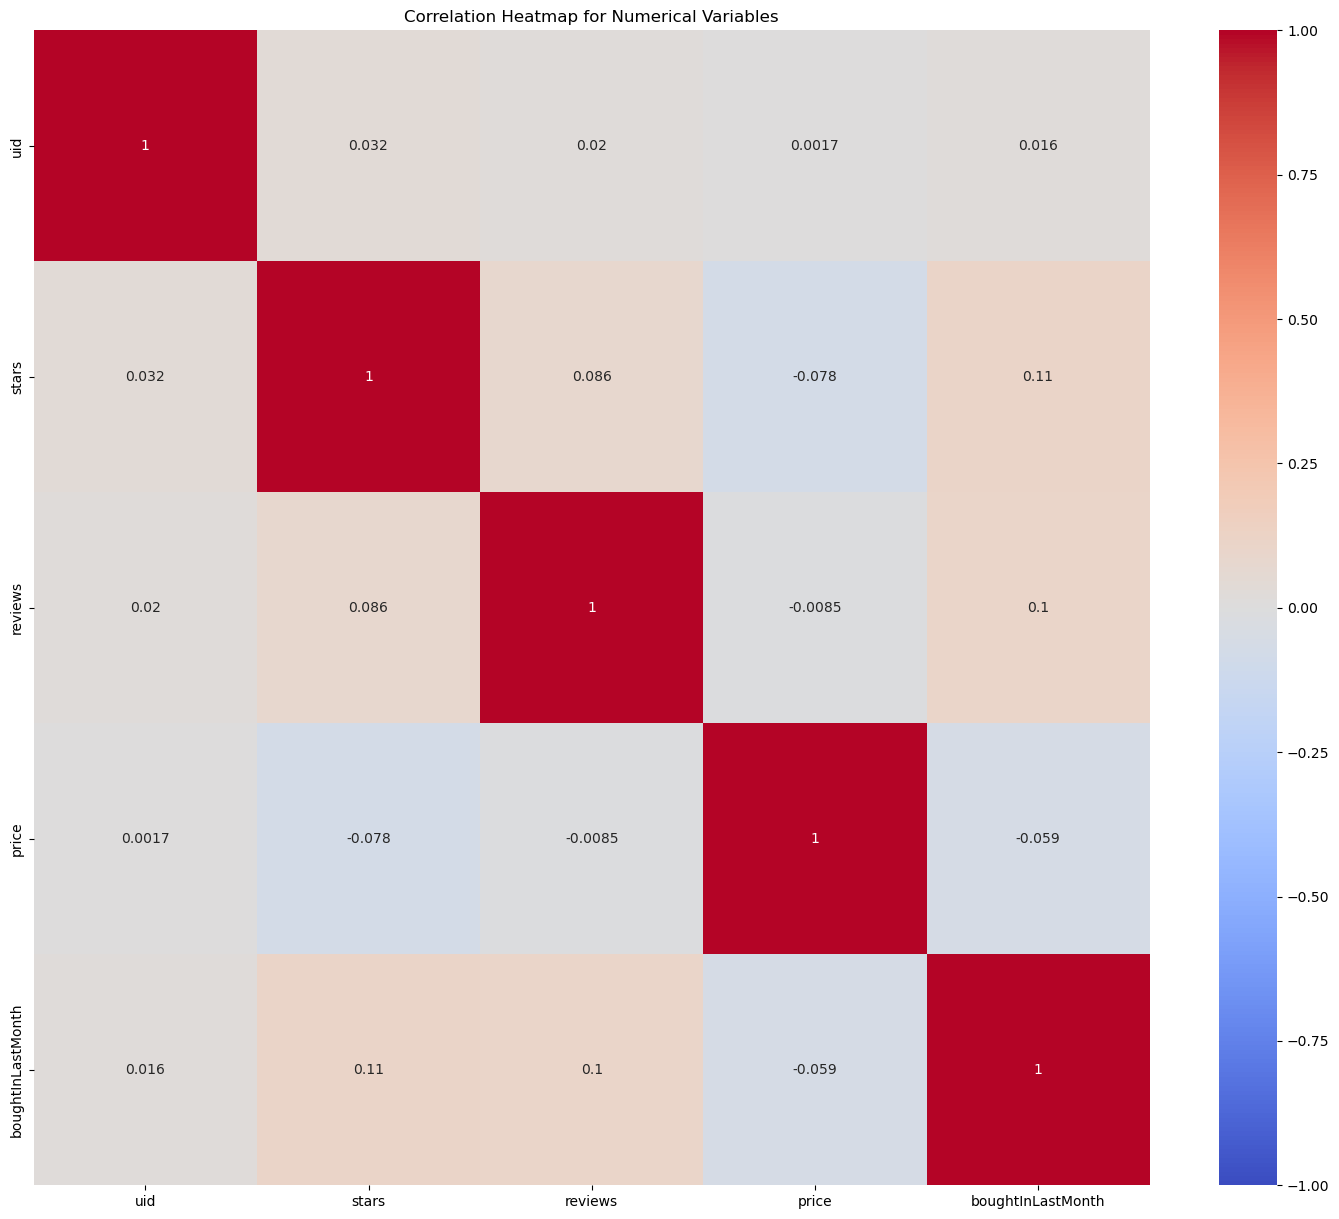

In [197]:
df_numerical = df.select_dtypes("number")
correlation_matrix = df_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", vmin= -1, vmax=)

plt.title("Correlation Heatmap for Numerical Variables")
plt.show()

In [198]:
#we don't see any strong correlations.

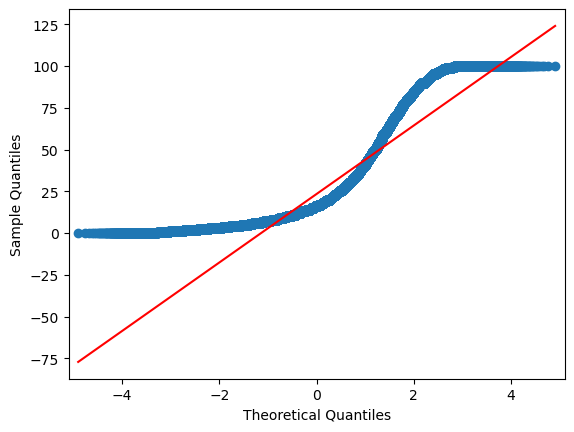

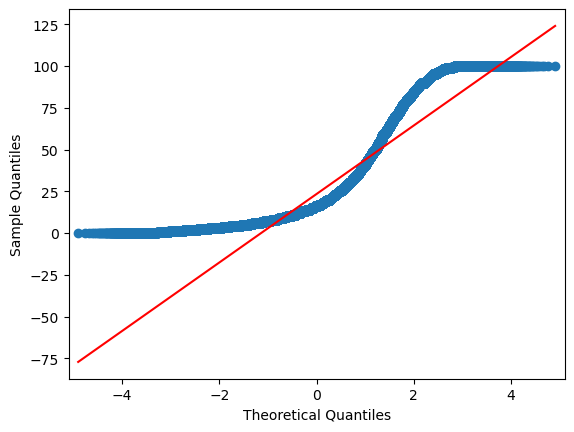

In [199]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'price' to check if its distribution follows a normal distribution
sm.qqplot(df['price'].dropna(), line='s')
#####the price does not follow a normal distribution

#### Insights: A significant correlation between price and rating was not seen. The correlation was very weak.
There were too many datapoints in the scatterplot to see a clear association, though ratings appeared to be diverse across all price points.
When looking at the association between all numerical variables, no strong associations were seen. The prices did not follow a normal distribution.


### Bonus
Do not filter for price outliers

In [202]:
df_o = pd.read_csv('../../amz_uk_price_prediction_dataset.csv')

<Axes: xlabel='price', ylabel='category'>

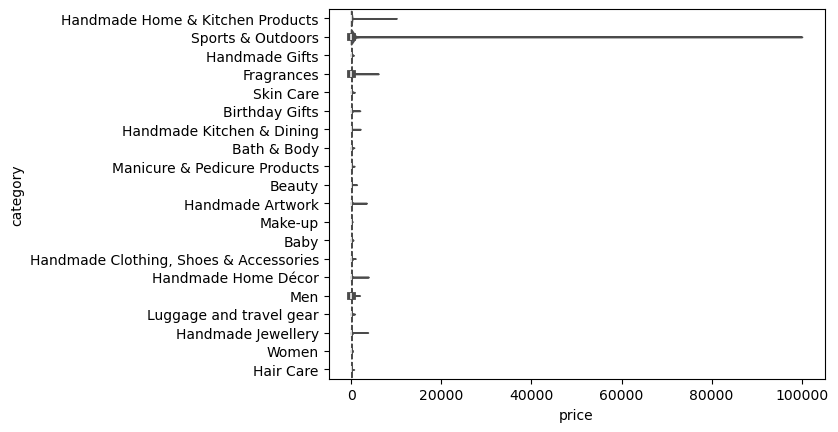

In [206]:
data_o= df_o.loc[df.category.isin(list_top_20)]
sns.violinplot(data=data_o, x='price', y='category', palette="coolwarm", hue='category', legend=False)
#this figure becomes difficult to read.

In [208]:
df_o.groupby('category')['price'].agg('median').sort_values(ascending=False)
#Laptops overtakes Desktop PCs as highest median.

category
Laptops                      1042.725
Desktop PCs                   810.400
Snowboards                    366.725
Home Audio Record Players     326.080
3D Printers                   319.000
                               ...   
Adapters                        7.050
Make-up                         7.000
Signs & Plaques                 6.990
Arts & Crafts                   5.990
Office Paper Products           4.380
Name: price, Length: 296, dtype: float64

<Axes: ylabel='category'>

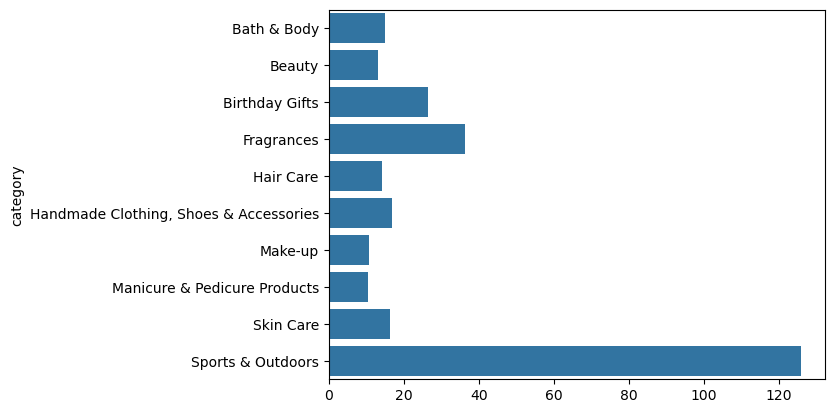

In [209]:
data1_o= df_o.groupby(df_o[df_o.category.isin(list_top_10)].category)['price'].agg('mean')
sns.barplot(y=data1_o.index, x=data1_o.values,  legend=False)
#Sports and Outdoors very clearly shows the highest mean across the top 10 categories, overtaking Fragrances.

In [210]:
df_o.groupby('category')['price'].agg('mean').sort_values(ascending=False)
#massive shift in the ranking here. Previously the top was Motherboards with a mean price of approximately 69 dollars, now we see Laptops
#with a mean price of 1087 dollars.

category
Laptops                  1087.987827
3D Printers              1018.036129
Desktop PCs               926.816064
Home Office Furniture     622.135898
Test & Measurement        559.382973
                            ...     
Bedding Accessories         8.835220
Adapters                    8.750197
Signs & Plaques             8.275136
Arts & Crafts               8.182523
Office Paper Products       7.047684
Name: price, Length: 296, dtype: float64

In [203]:
df_o.price.corr(df_o['stars'], method='pearson')
#still no correlation seen.

np.float64(-0.1249067326214861)

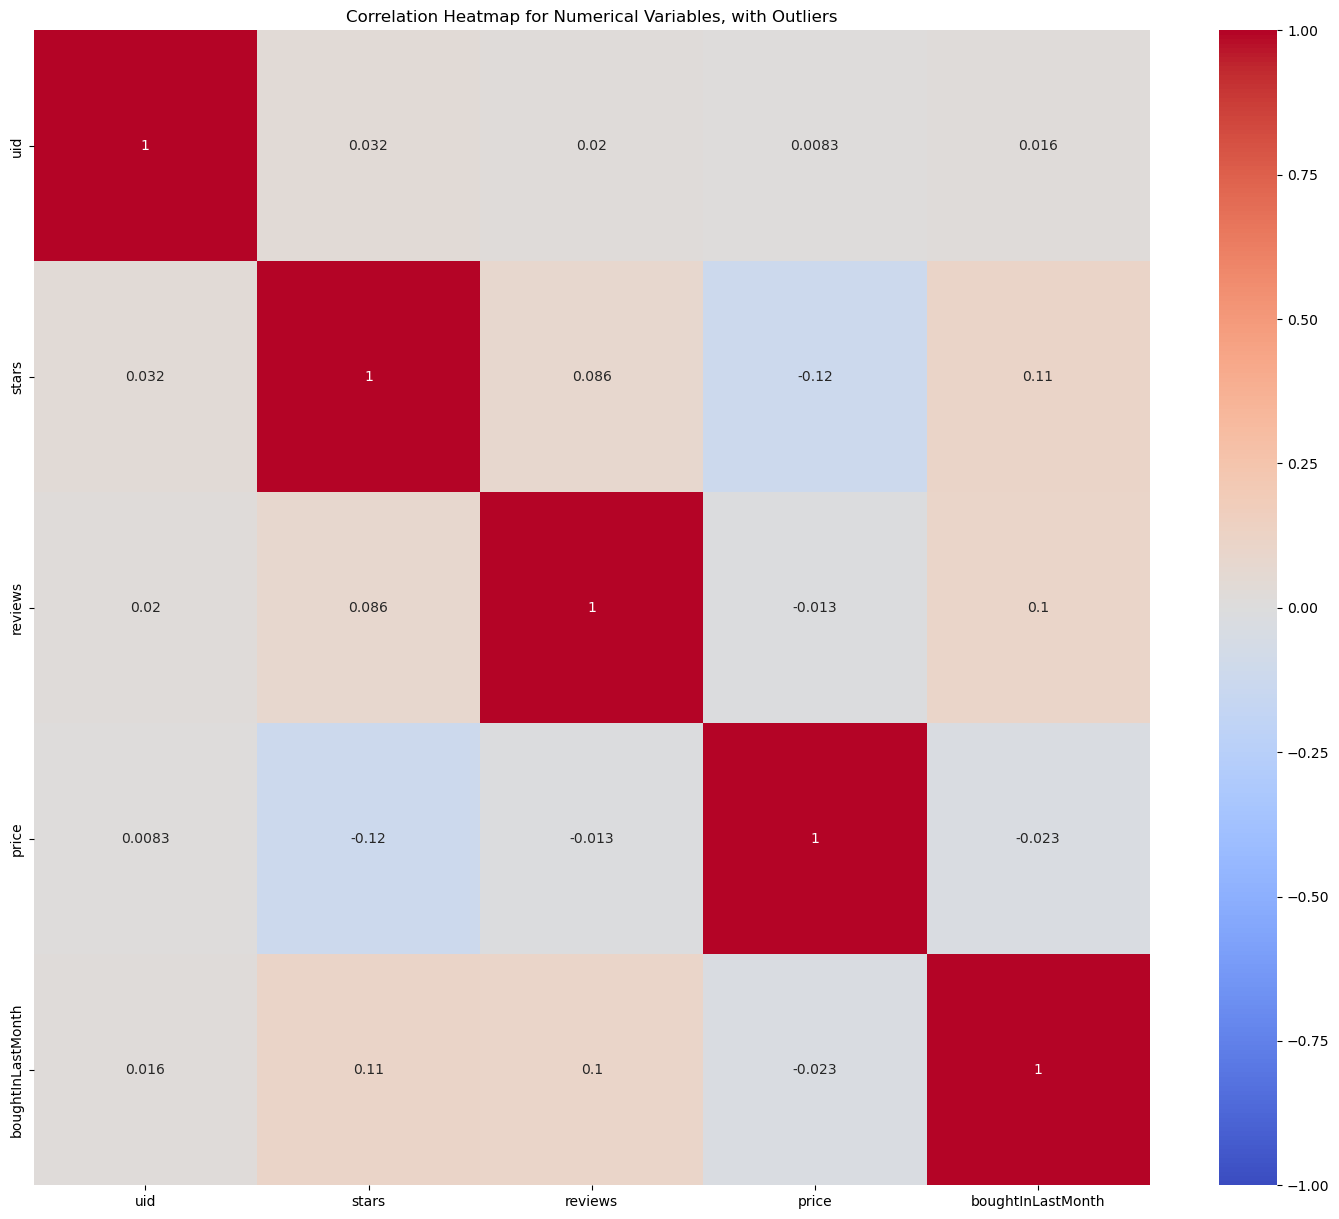

In [204]:
df_o_numerical = df_o.select_dtypes("number")
correlation_matrix_o = df_o_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix_o, annot=True, cmap="coolwarm", vmin= -1, vmax=1)

plt.title("Correlation Heatmap for Numerical Variables, with Outliers")
plt.show()
#still no correlations observed.

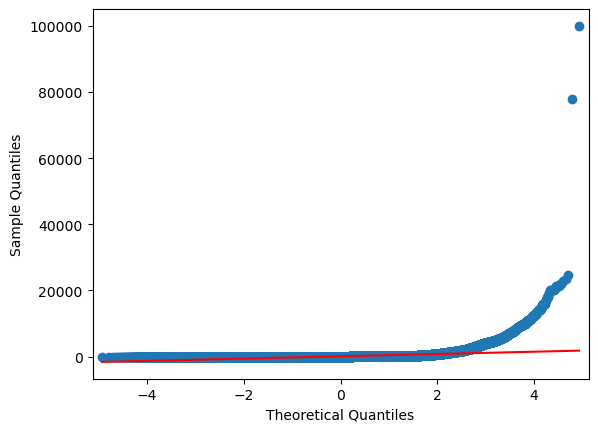

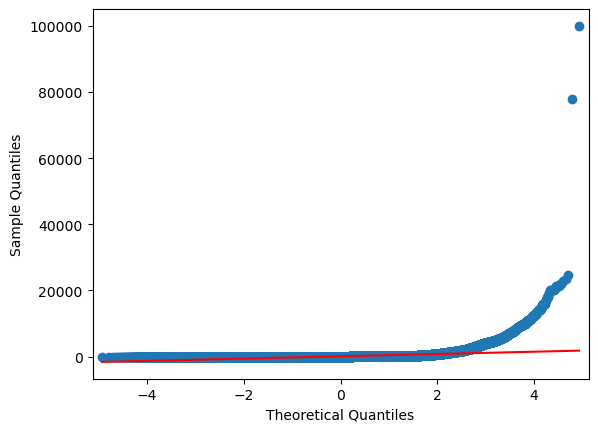

In [205]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'price' to check if its distribution follows a normal distribution
sm.qqplot(df_o['price'].dropna(), line='s')
#####the price appears to be closer to following a normal distribution, though only up to the theoretical quantile of 2.

#### Insights:
By adding back the outliers, we see large shifts in the categories that have the highest mean and median values, as well as a shift to a more normal distribution. Electronics categories appear to rise in mean and median values, perhaps suggesting that the values excluded were not true outliers, but that electronics are more expensive than the median products in the range. Similarly Sports and Outdoors saw a rise. It may be wise to consider more deeply the expected price ranges across different categories when applying an outlier filter.